In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix, accuracy_score

In [2]:
df = pd.read_csv("E-commerce Customer Behavior - Sheet1.csv")
print(df.head())

   Customer ID  Gender  Age           City Membership Type  Total Spend  \
0          101  Female   29       New York            Gold      1120.20   
1          102    Male   34    Los Angeles          Silver       780.50   
2          103  Female   43        Chicago          Bronze       510.75   
3          104    Male   30  San Francisco            Gold      1480.30   
4          105    Male   27          Miami          Silver       720.40   

   Items Purchased  Average Rating  Discount Applied  \
0               14             4.6              True   
1               11             4.1             False   
2                9             3.4              True   
3               19             4.7             False   
4               13             4.0              True   

   Days Since Last Purchase Satisfaction Level  
0                        25          Satisfied  
1                        18            Neutral  
2                        42        Unsatisfied  
3               

In [4]:
print(df.isnull().sum())

Customer ID                 0
Gender                      0
Age                         0
City                        0
Membership Type             0
Total Spend                 0
Items Purchased             0
Average Rating              0
Discount Applied            0
Days Since Last Purchase    0
Satisfaction Level          2
dtype: int64


In [5]:
print(df.dtypes)

Customer ID                   int64
Gender                       object
Age                           int64
City                         object
Membership Type              object
Total Spend                 float64
Items Purchased               int64
Average Rating              float64
Discount Applied               bool
Days Since Last Purchase      int64
Satisfaction Level           object
dtype: object


In [7]:
df.describe()

,Customer ID,Age,Total Spend,Items Purchased,Average Rating,Days Since Last Purchase
count,350.000000,350.000000,350.000000,350.000000,350.000000,350.000000
mean,275.500000,33.597143,845.381714,12.600000,4.019143,26.588571
std,101.180532,4.870882,362.058695,4.155984,0.580539,13.440813
min,101.000000,26.000000,410.800000,7.000000,3.000000,9.000000
25%,188.250000,30.000000,502.000000,9.000000,3.500000,15.000000
50%,275.500000,32.500000,775.200000,12.000000,4.100000,23.000000
75%,362.750000,37.000000,1160.600000,15.000000,4.500000,38.000000
max,450.000000,43.000000,1520.100000,21.000000,4.900000,63.000000


In [8]:
df = df.dropna()

In [9]:
X = df.drop(["Satisfaction Level", "Customer ID"], axis=1)
y = df["Satisfaction Level"]

In [10]:
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y)
X = pd.get_dummies(X, drop_first=False)

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

In [12]:
k = min(8, X_train.shape[1])
selector = SelectKBest(score_func=chi2, k=k)
X_train_selected = selector.fit_transform(X_train, y_train)
X_test_selected = selector.transform(X_test)
print("Selected Features:")
print(X.columns[selector.get_support()])

Selected Features:
Index(['Total Spend', 'Items Purchased', 'Discount Applied',
       'Days Since Last Purchase', 'City_Houston', 'City_Miami',
       'City_San Francisco', 'Membership Type_Gold'],
      dtype='object')


In [13]:
classifier = RandomForestClassifier(n_estimators=100, random_state=42)
classifier.fit(X_train_selected, y_train)

RandomForestClassifier(random_state=42)

In [14]:
prediction = classifier.predict(X_test_selected)
print("Prediction:")
print(prediction[:20])

Prediction:
[2 2 1 0 2 2 2 1 2 0 1 1 1 0 2 0 2 1 0 2]


In [15]:
print("Accuracy:")
print(accuracy_score(y_test, prediction))

Accuracy:
1.0


In [16]:
print("Classification Report:")
print(classification_report(y_test, prediction, target_names=label_encoder.classes_))

Classification Report:
              precision    recall  f1-score   support

     Neutral       1.00      1.00      1.00        22
   Satisfied       1.00      1.00      1.00        25
 Unsatisfied       1.00      1.00      1.00        23

    accuracy                           1.00        70
   macro avg       1.00      1.00      1.00        70
weighted avg       1.00      1.00      1.00        70



In [17]:
cm = confusion_matrix(y_test, prediction)
print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[22  0  0]
 [ 0 25  0]
 [ 0  0 23]]


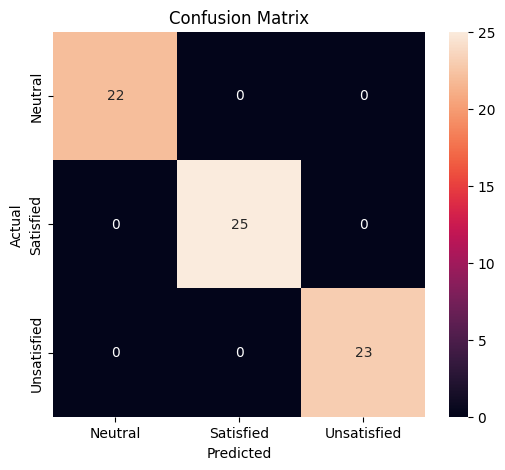

In [18]:
plt.figure(figsize=(6, 5))
sns.heatmap(cm,annot=True,fmt="d",xticklabels=label_encoder.classes_,yticklabels=label_encoder.classes_)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()